# Studded Tire Checkpoint – Student Starter Notebook
**DSP – Image Processing Final Project**

Read the assignment on Moodle first. This notebook gives you the structure, the data loading and the evaluation helpers. **You implement the parts marked `TODO`** (they raise `NotImplementedError` until you do).

**How to work**
1. In Colab upload `dataset_v2_split.zip` and `best.pt` to `/content` (or mount Drive) and set the paths in the CONFIG cell.
2. Run the cells top to bottom. Implement the helper functions in the *helper library* cell first; the **self-check** cell below it tells you whether they behave correctly.
3. After each part write your answers in the **✏️ Your answer** cells and add your own figures where the assignment asks for them.
4. Parameters are tuned on **validation** only. The test set is used for the final numbers.
5. You may add cells, but do not change the given helper functions, the seeds, or the original data.

Report failures honestly. You must be able to explain every line you submit.

## Part 0 – Setup and data audit

In [13]:
!pip -q install ultralytics scikit-image
import os, zipfile, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

In [14]:
import re, random, time
import numpy as np, cv2
from pathlib import Path
from skimage.feature import hog
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

SEED = 42

# ---------- Part 1: classical toolbox ----------
def clahe_gray(g, clip=2.0, tile=8):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(g)

def stud_candidates(bgr, tophat_k=15, min_thr=40, min_area=6, max_area=400, debug=False):
    """Classical stud-candidate detector.
    Returns [count, mean_area, std_area, area_fraction] (area_fraction = total candidate area / image area).
    If debug=True return (feats, tophat_img, binary_img, list_of_centroids) instead.
    """
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY) if bgr.ndim == 3 else bgr.copy()
    enhanced = clahe_gray(gray)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(tophat_k), int(tophat_k)))
    tophat_img = cv2.morphologyEx(enhanced, cv2.MORPH_TOPHAT, kernel)

    otsu_thr, _ = cv2.threshold(tophat_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    thr = max(float(otsu_thr), float(min_thr))
    binary_img = ((tophat_img >= thr).astype(np.uint8)) * 255

    num_labels, _, stats, centroids = cv2.connectedComponentsWithStats(binary_img)
    kept_areas = []
    kept_centroids = []

    for i in range(1, num_labels):
        area = float(stats[i, cv2.CC_STAT_AREA])
        if min_area <= area <= max_area:
            kept_areas.append(area)
            kept_centroids.append((float(centroids[i, 0]), float(centroids[i, 1])))

    img_area = float(gray.shape[0] * gray.shape[1])
    if len(kept_areas) > 0:
        feats = [
            float(len(kept_areas)),
            float(np.mean(kept_areas)),
            float(np.std(kept_areas)),
            float(np.sum(kept_areas) / img_area),
        ]
    else:
        feats = [0.0, 0.0, 0.0, 0.0]

    if debug:
        return (feats, tophat_img, binary_img, kept_centroids)
    return feats

def classical_features(bgr):
    """Feature vector = stud_candidates(bgr) (4 numbers) followed by a HOG descriptor.
    TODO: resize to 128x128, grayscale, CLAHE, then skimage.feature.hog with orientations=9,
    pixels_per_cell=(16, 16), cells_per_block=(2, 2). Return one 1-D numpy array (1768 values)."""
    blob_feats = np.asarray(stud_candidates(bgr), dtype=np.float32)

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY) if bgr.ndim == 3 else bgr.copy()
    gray_128 = cv2.resize(gray, (128, 128), interpolation=cv2.INTER_AREA)
    clahe_128 = clahe_gray(gray_128)

    hog_feats = hog(
        clahe_128,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        feature_vector=True,
    ).astype(np.float32)

    return np.concatenate([blob_feats, hog_feats]).ravel()

# ---------- Part 4: degradations ----------
def motion_psf(L):
    """Horizontal motion-blur kernel: a 1 x L float32 array, every element 1/L (so it sums to 1)."""
    return np.full((1, int(L)), 1.0 / float(L), dtype=np.float32)

def motion_blur(img, L):
    """Blur img with the horizontal line kernel of length L.
    TODO: cv2.filter2D with motion_psf(L) and borderType=cv2.BORDER_REFLECT. Output stays uint8."""
    psf = motion_psf(L)
    blurred = cv2.filter2D(img, -1, psf, borderType=cv2.BORDER_REFLECT)
    return np.clip(np.round(blurred), 0, 255).astype(np.uint8)

def darken(img, gamma):
    """Gamma darkening: out = 255 * (img/255) ** gamma, clipped to 0..255, returned as uint8 (gamma > 1 darkens)."""
    if gamma == 1:
        return img.copy()
    out = 255.0 * np.power(img.astype(np.float32) / 255.0, float(gamma))
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def add_noise(img, sigma, rng):
    """Add zero-mean Gaussian noise with standard deviation sigma (grey levels).
    Use the given numpy Generator `rng` (rng.normal), clip to 0..255, round, return uint8."""
    noise = rng.normal(0.0, float(sigma), size=img.shape)
    out = img.astype(np.float32) + noise.astype(np.float32)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def build_conditions():
    C = {"original": lambda im, r: im}
    for L in (5, 15, 25, 35):
        C[f"blur_L{L}"] = lambda im, r, L=L: motion_blur(im, L)
    for g, s in ((1.5, 5), (2.5, 15)):
        C[f"dark_g{g}_s{s}"] = lambda im, r, g=g, s=s: add_noise(darken(im, g), s, r)
    C["combined"] = lambda im, r: add_noise(darken(motion_blur(im, 15), 2.0), 10, r)
    return C

def degrade_set(imgs, fn, seed=SEED):
    return [fn(im, np.random.default_rng(seed + i)) for i, im in enumerate(imgs)]

# ---------- Part 5: restoration ----------
def psf2otf(psf, shape):
    big = np.zeros(shape, np.float32)
    h, w = psf.shape
    big[:h, :w] = psf
    return np.fft.fft2(np.roll(big, (-(h // 2), -(w // 2)), axis=(0, 1)))

def wiener_deconv(img, psf, K):
    """Frequency-domain Wiener deconvolution, applied to each colour channel separately."""
    H = psf2otf(psf, img.shape[:2])
    W = np.conj(H) / (np.abs(H) ** 2 + float(K))
    img_f = img.astype(np.float32)

    if img_f.ndim == 2:
        restored = np.real(np.fft.ifft2(np.fft.fft2(img_f) * W))
    else:
        channels = [
            np.real(np.fft.ifft2(np.fft.fft2(img_f[..., c]) * W))
            for c in range(img_f.shape[2])
        ]
        restored = np.stack(channels, axis=-1)

    return np.clip(np.round(restored), 0, 255).astype(np.uint8)

def clahe_bgr(img, clip=2.0):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab[..., 0] = clahe_gray(lab[..., 0], clip)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

def restore_lowlight(img, gamma, denoise_h=5, use_clahe=True):
    """Low-light restoration."""
    out = darken(img, 1.0 / float(gamma))
    if denoise_h and denoise_h > 0:
        out = cv2.fastNlMeansDenoisingColored(out, None, float(denoise_h), float(denoise_h), 7, 21)
    if use_clahe:
        out = clahe_bgr(out)
    return out.astype(np.uint8)

def psnr_ssim(ref, test):
    return (psnr_fn(ref, test, data_range=255),
            ssim_fn(ref, test, data_range=255, channel_axis=2))

# ---------- metrics ----------
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="binary", pos_label=1, zero_division=0)
    return dict(accuracy=accuracy_score(y, p), precision=pr, recall=rc, f1=f1)

def bootstrap_ci(y, p, n=1000, seed=SEED, alpha=0.05):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    accs = [np.mean(y[i] == p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return tuple(np.quantile(accs, [alpha / 2, 1 - alpha / 2]))

def threshold_for_precision(y, score, target=0.95):
    ts = np.unique(score)
    ok = [t for t in ts if (score >= t).sum() and np.mean(y[score >= t] == 1) >= target]
    return min(ok) if ok else 0.5

In [15]:
# ===== SELF-CHECK: run after implementing the helper functions =====
def _check(name, fn):
    try:
        ok = bool(fn()); print(("PASS  " if ok else "FAIL  ") + name)
    except NotImplementedError:
        print("TODO  " + name)
    except Exception as e:
        print(f"ERROR {name}: {type(e).__name__}: {e}")

_rng = np.random.default_rng(0)
_img = np.full((200, 260, 3), 70, np.uint8); cv2.circle(_img, (130, 100), 80, (25, 25, 25), -1)
for a in np.linspace(0, 6.28, 24): cv2.circle(_img, (int(130 + 60 * np.cos(a)), int(100 + 60 * np.sin(a))), 3, (230, 230, 230), -1)

_check("motion_psf: shape (1, L) and sums to 1", lambda: motion_psf(15).shape == (1, 15) and abs(float(motion_psf(15).sum()) - 1) < 1e-5)
_check("motion_blur: uint8, same shape, smoother than input", lambda: (lambda b: b.dtype == np.uint8 and b.shape == _img.shape and
       np.abs(np.diff(b.astype(int), axis=1)).mean() < np.abs(np.diff(_img.astype(int), axis=1)).mean())(motion_blur(_img, 15)))
_check("darken: uint8, darker, gamma=1 leaves image unchanged", lambda: darken(_img, 2.0).dtype == np.uint8 and darken(_img, 2.0).mean() < _img.mean() and np.array_equal(darken(_img, 1.0), _img))
_check("add_noise: uint8, noise std close to sigma", lambda: (lambda n: n.dtype == np.uint8 and 8 < (n.astype(float) - 128).std() < 12)(add_noise(np.full((200, 200, 3), 128, np.uint8), 10, np.random.default_rng(1))))
_check("add_noise: same seed gives same result", lambda: np.array_equal(add_noise(_img, 10, np.random.default_rng(5)), add_noise(_img, 10, np.random.default_rng(5))))
_check("wiener_deconv: improves PSNR of a blurred image (known kernel)", lambda: (lambda b: psnr_ssim(_img, wiener_deconv(b, motion_psf(15), 1e-3))[0] > psnr_ssim(_img, b)[0])(motion_blur(_img, 15)))
_check("wiener_deconv: uint8 and same shape", lambda: (lambda r: r.dtype == np.uint8 and r.shape == _img.shape)(wiener_deconv(motion_blur(_img, 15), motion_psf(15), 1e-3)))
_check("stud_candidates: returns 4 numbers, finds blobs on the test pattern", lambda: (lambda f: len(f) == 4 and f[0] >= 10)(stud_candidates(_img)))
_check("classical_features: 1-D vector of length 1768", lambda: classical_features(_img).shape == (1768,))
_check("restore_lowlight: uint8, brighter than the dark input", lambda: (lambda d: restore_lowlight(d, 2.0).dtype == np.uint8 and restore_lowlight(d, 2.0).mean() > d.mean())(darken(_img, 2.0)))

PASS  motion_psf: shape (1, L) and sums to 1
PASS  motion_blur: uint8, same shape, smoother than input
PASS  darken: uint8, darker, gamma=1 leaves image unchanged
PASS  add_noise: uint8, noise std close to sigma
PASS  add_noise: same seed gives same result
PASS  wiener_deconv: improves PSNR of a blurred image (known kernel)
PASS  wiener_deconv: uint8 and same shape
PASS  stud_candidates: returns 4 numbers, finds blobs on the test pattern
PASS  classical_features: 1-D vector of length 1768
PASS  restore_lowlight: uint8, brighter than the dark input


In [16]:
# ===== CONFIG: edit these paths =====
ZIP_PATH   = "/content/dataset_v2_split.zip"   # or the unzipped folder, set UNZIPPED=True below
MODEL_PATH = "/content/best.pt"
WORK       = Path("/content/data")             # data/original, data/blur, data/lowlight, data/restored ...
MAX_SIDE   = 512                               # images are resized so the longest side <= MAX_SIDE (speed)
POS_NAME   = None                              # None = auto-detect the 'studded' class folder; or set e.g. "studded"
# ====================================
random.seed(SEED); np.random.seed(SEED)
src = WORK / "original"
if not src.exists():
    src.mkdir(parents=True)
    with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(src)

def find_splits(root):
    found = {}
    for p in sorted(Path(root).rglob("*"), key=lambda p: len(p.parts)):
        n = {"valid": "val", "validation": "val"}.get(p.name.lower(), p.name.lower())
        if p.is_dir() and n in ("train", "val", "test") and n not in found: found[n] = p
    return found

SPLIT_DIRS = find_splits(src)
print({k: str(v) for k, v in SPLIT_DIRS.items()})
assert set(SPLIT_DIRS) == {"train", "val", "test"}, "Could not find train/val/test folders - check the zip structure"

CLASS_NAMES = sorted(d.name for d in SPLIT_DIRS["train"].iterdir() if d.is_dir())
norm = lambda s: re.sub("[^a-z]", "", s.lower())
if POS_NAME is None:
    cand = [c for c in CLASS_NAMES if not re.match(r"(non|no|un|without|nst)", norm(c))]
    assert len(cand) == 1, f"Set POS_NAME manually, classes: {CLASS_NAMES}"
    POS_NAME = cand[0]
NEG_NAME = [c for c in CLASS_NAMES if c != POS_NAME][0]
print("classes:", CLASS_NAMES, "| positive (studded) =", POS_NAME)

def load_split(split):
    imgs, y, paths = [], [], []
    for lab, cname in ((0, NEG_NAME), (1, POS_NAME)):
        for f in sorted((SPLIT_DIRS[split] / cname).glob("*")):
            if f.suffix.lower() not in (".jpg", ".jpeg", ".png", ".bmp", ".webp"): continue
            im = cv2.imread(str(f))
            if im is None: continue
            s = MAX_SIDE / max(im.shape[:2])
            if s < 1: im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
            imgs.append(im); y.append(lab); paths.append(f)
    return dict(imgs=imgs, y=np.array(y), paths=paths)

DATA = {s: load_split(s) for s in ("train", "val", "test")}
audit = pd.DataFrame({s: {"n_images": len(d["y"]), "studded": int(d["y"].sum()), "non-studded": int((d["y"] == 0).sum()),
                          "median_size (HxW)": "x".join(str(int(v)) for v in np.median([i.shape[:2] for i in d["imgs"]], 0))} for s, d in DATA.items()}).T
display(audit)

{'train': '/content/data/original/dataset_v2_split/train', 'val': '/content/data/original/dataset_v2_split/val', 'test': '/content/data/original/dataset_v2_split/test'}
classes: ['nst', 'st'] | positive (studded) = st


,n_images,studded,non-studded,median_size (HxW)
train,350,175,175,261x261
val,76,38,38,261x261
test,74,37,37,261x261


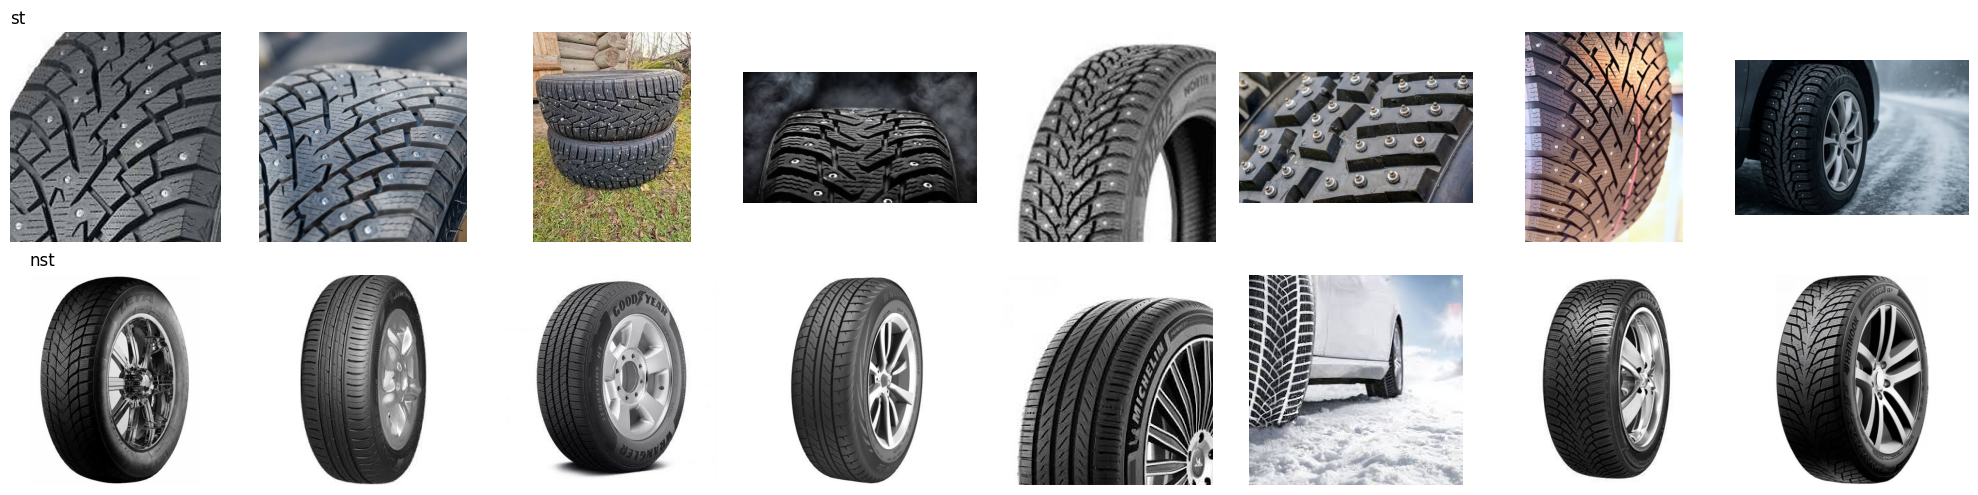

In [17]:
# image grid: 8 per class (train)
fig, ax = plt.subplots(2, 8, figsize=(20, 5))
for r, lab in enumerate((1, 0)):
    idx = np.where(DATA["train"]["y"] == lab)[0][:8]
    for c, i in enumerate(idx):
        ax[r, c].imshow(cv2.cvtColor(DATA["train"]["imgs"][i], cv2.COLOR_BGR2RGB)); ax[r, c].axis("off")
    ax[r, 0].set_title(POS_NAME if lab else NEG_NAME, loc="left")
plt.tight_layout(); plt.show()

In [18]:
# Near-duplicate audit (data leakage check): perceptual difference hash (dHash, 256 bits) across ALL splits
def dhash(im, n=16):
    g = cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (n + 1, n), interpolation=cv2.INTER_AREA)
    return (g[:, 1:] > g[:, :-1]).flatten()

ALL = [(s, i) for s in ("train", "val", "test") for i in range(len(DATA[s]["y"]))]
HASH = np.stack([dhash(DATA[s]["imgs"][i]) for s, i in ALL])
DIST = (HASH[:, None, :] != HASH[None, :, :]).sum(-1); np.fill_diagonal(DIST, 999)
THR = 10                                           # <= 10 of 256 bits differ  ->  practically the same picture
pairs = [(a, b) for a, b in zip(*np.where(DIST <= THR)) if a < b]
cross = [(a, b) for a, b in pairs if ALL[a][0] != ALL[b][0]]
conflict = [(a, b) for a, b in pairs if DATA[ALL[a][0]]["y"][ALL[a][1]] != DATA[ALL[b][0]]["y"][ALL[b][1]]]
print(f"near-duplicate pairs: {len(pairs)} | across different splits (leakage): {len(cross)} | with conflicting labels: {len(conflict)}")
for s in ("val", "test"):
    n_leak = len({a if ALL[a][0] == s else b for a, b in cross if s in (ALL[a][0], ALL[b][0])})
    print(f"  {s}: {n_leak}/{len(DATA[s]['y'])} images have a near-duplicate in another split")

near-duplicate pairs: 26 | across different splits (leakage): 11 | with conflicting labels: 1
  val: 5/76 images have a near-duplicate in another split
  test: 3/74 images have a near-duplicate in another split


**Write:** what do duplicates between train and test do to your accuracy estimate? How would you fix the split? (You do not modify the original data: report and discuss, or build a cleaned copy in your own folder.)

✏️ **Your answer:**

Duplicates or near-duplicates shared between the train and test splits introduce data leakage, which artificially inflates test accuracy, precision, recall, and F1-score because the model can recognize memorized images rather than generalizing to unseen tires. As a result, the test score becomes an over-optimistic estimate of real-world roadside performance. To fix this without modifying the original dataset, we can cluster near-duplicate images first using perceptual hashing (dHash with a Hamming distance threshold <= 10) and apply a group-aware stratified split (StratifiedGroupKFold or GroupShuffleSplit) into a separate cleaned directory, ensuring every duplicate cluster belongs exclusively to train, val, or test.

**Write (3 sentences):** name three characteristics that make this task hard (e.g. stud size vs. image size, reflections on wet tires, tire tread patterns that look like studs, viewing angle).

✏️ **Your answer:**

Metal studs occupy only a tiny fraction of the total image area (often just a few pixels wide), making them easy to miss when obscured inside deep tread grooves or degraded by motion blur. Specular reflections on wet rubber, ice crystals, embedded road gravel, and metallic wheel-rim edges create small bright highlights that closely resemble stud pins. Finally, wide variations in camera viewing angle, wheel rotation, and uneven roadside lighting substantially alter both stud visibility and background tread texture across passing vehicles.

## Part 1 – Classical image processing toolbox

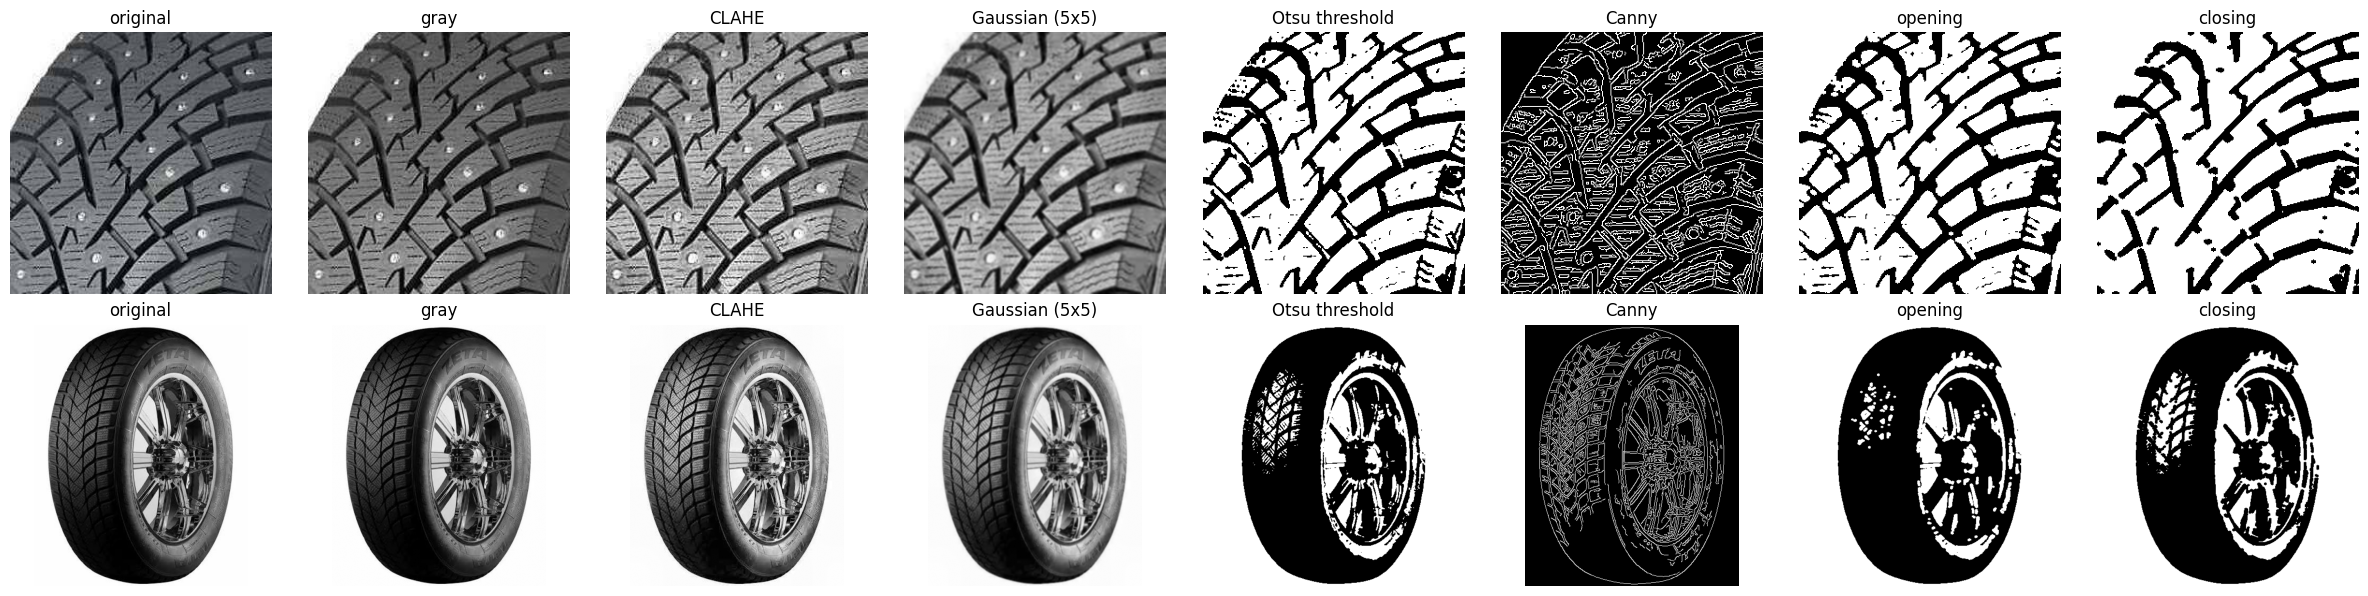

In [19]:
def toolbox(bgr):
    # Return a list of (name, image) pairs, in this order:
    # original (convert to RGB for display), gray, CLAHE, Gaussian (5x5), Otsu threshold, Canny, opening, closing.
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    clahe = clahe_gray(gray, clip=2.0, tile=8)
    gauss = cv2.GaussianBlur(clahe, (5, 5), 1.0)
    _, otsu = cv2.threshold(gauss, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    canny = cv2.Canny(gauss, 60, 150)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    opening = cv2.morphologyEx(otsu, cv2.MORPH_OPEN, kernel)
    closing = cv2.morphologyEx(otsu, cv2.MORPH_CLOSE, kernel)
    return [
        ("original", rgb),
        ("gray", gray),
        ("CLAHE", clahe),
        ("Gaussian (5x5)", gauss),
        ("Otsu threshold", otsu),
        ("Canny", canny),
        ("opening", opening),
        ("closing", closing),
    ]

ex = {lab: np.where(DATA["train"]["y"] == lab)[0][0] for lab in (1, 0)}
fig, ax = plt.subplots(2, 8, figsize=(24, 6))
for r, lab in enumerate((1, 0)):
    for c, (name, im) in enumerate(toolbox(DATA["train"]["imgs"][ex[lab]])):
        ax[r, c].imshow(im, cmap=None if im.ndim == 3 else "gray"); ax[r, c].set_title(name); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

### Stud candidate detector
`stud_candidates()` = CLAHE → white top-hat → Otsu threshold → connected components → size filter.
**Task:** tune `tophat_k`, `min_area`, `max_area` on the **validation** set (do not touch test), then compare candidate counts of both classes.

Tuned on val -> tophat_k=9, min_area=4, max_area=250 (count threshold >= 122, val F1 = 0.691)


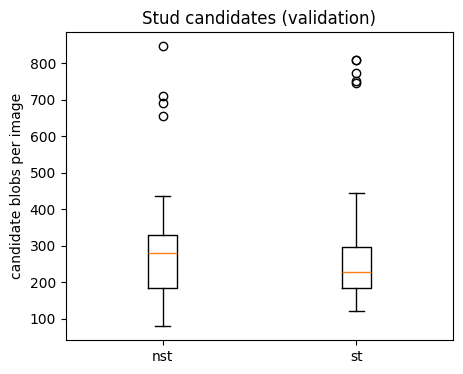

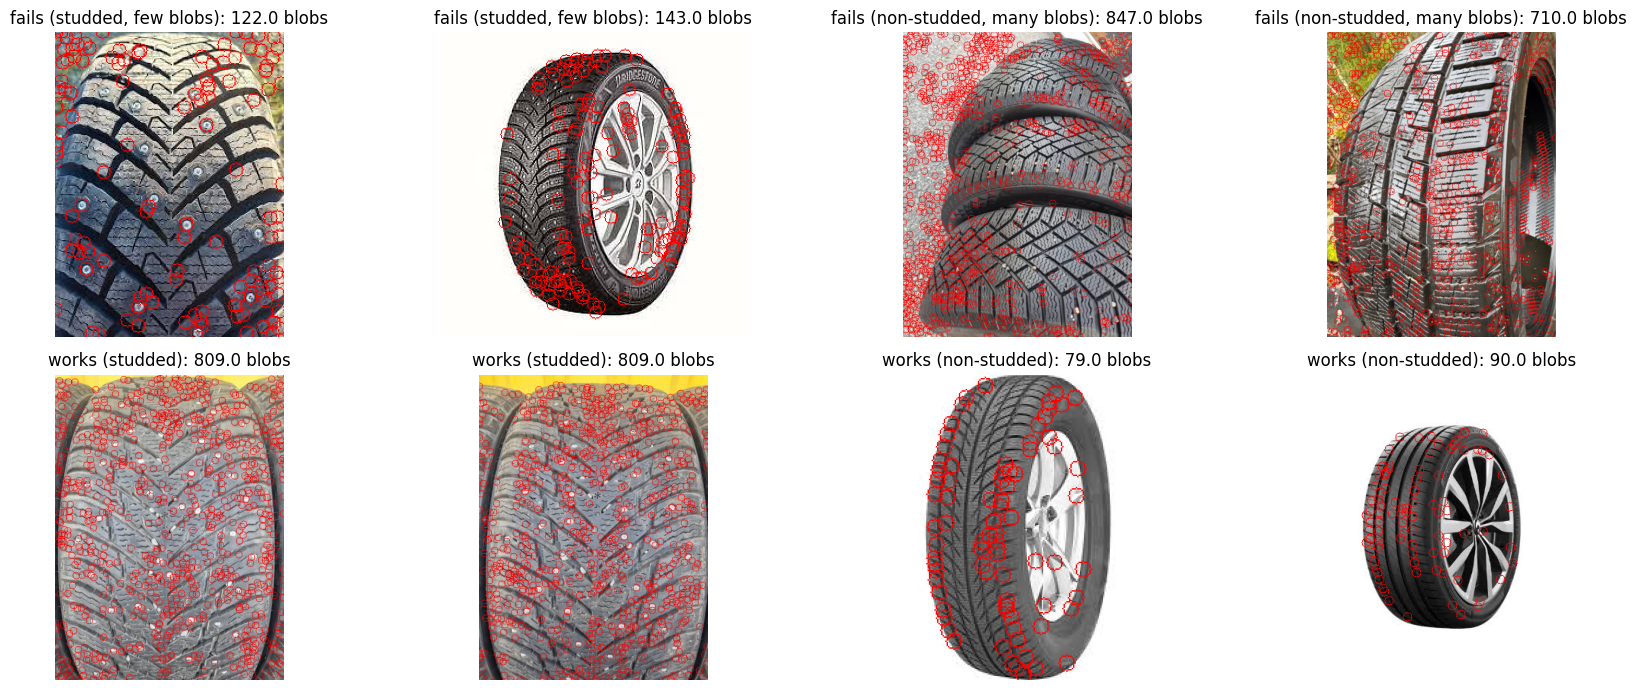

In [20]:
# --- Tune (tophat_k, min_area, max_area) on VALIDATION SET ONLY ---
val_imgs = DATA["val"]["imgs"]
val_y = DATA["val"]["y"]

best_score = -1.0
best_params = (15, 6, 400)  # (tophat_k, min_area, max_area)
best_thr = 5

for tk in (9, 13, 15, 19):
    for min_a in (4, 6, 10):
        for max_a in (250, 400, 600):
            counts = np.array([
                stud_candidates(im, tophat_k=tk, min_area=min_a, max_area=max_a)[0]
                for im in val_imgs
            ])
            for c_thr in np.unique(counts):
                preds = (counts >= c_thr).astype(int)
                f1 = metrics(val_y, preds)["f1"]
                if f1 > best_score:
                    best_score = f1
                    best_params = (tk, min_a, max_a)
                    best_thr = int(c_thr)

print(f"Tuned on val -> tophat_k={best_params[0]}, min_area={best_params[1]}, max_area={best_params[2]} "
      f"(count threshold >= {best_thr}, val F1 = {best_score:.3f})")

# Apply tuned parameters as defaults so Part 1 & Part 2 use them automatically
stud_candidates.__defaults__ = (best_params[0], 40, best_params[1], best_params[2], False)

# --- Compare candidate counts and visualize successes vs. failures ---
cnt = {s: np.array([stud_candidates(im)[0] for im in DATA[s]["imgs"]]) for s in ("train", "val")}
plt.figure(figsize=(5, 4))
plt.boxplot([cnt["val"][DATA["val"]["y"] == 0], cnt["val"][DATA["val"]["y"] == 1]]); plt.xticks([1, 2], [NEG_NAME, POS_NAME])
plt.ylabel("candidate blobs per image"); plt.title("Stud candidates (validation)"); plt.show()

# 2 successes and 2 failures: studded images with the fewest blobs / non-studded with the most
v = DATA["val"]; pos = np.where(v["y"] == 1)[0]; neg = np.where(v["y"] == 0)[0]
picks = [("works (studded)", pos[np.argsort(-cnt["val"][pos])[:2]]), ("fails (studded, few blobs)", pos[np.argsort(cnt["val"][pos])[:2]]),
         ("works (non-studded)", neg[np.argsort(cnt["val"][neg])[:2]]), ("fails (non-studded, many blobs)", neg[np.argsort(-cnt["val"][neg])[:2]])]
fig, ax = plt.subplots(2, 4, figsize=(18, 7)); k = 0
for title, idxs in picks[1:2] + picks[3:4] + picks[0:1] + picks[2:3]:
    for i in idxs:
        feats, th, bw, cen = stud_candidates(v["imgs"][i], debug=True)
        im = cv2.cvtColor(v["imgs"][i].copy(), cv2.COLOR_BGR2RGB)
        for (x, y_) in cen: cv2.circle(im, (int(x), int(y_)), 6, (255, 0, 0), 1)
        ax[k // 4, k % 4].imshow(im); ax[k // 4, k % 4].set_title(f"{title}: {feats[0]} blobs"); ax[k // 4, k % 4].axis("off"); k += 1
plt.tight_layout(); plt.show()

**Write:** why does the detector succeed on some images and fail on others? (Think: wet reflections, tread edges, shadows, stud size in pixels.)

✏️ **Your answer:**

The detector succeeds on well-lit, close-range tires where bright, circular tungsten-carbide stud heads stand out sharply against matte dark rubber: CLAHE boosts local contrast, the morphological white top-hat filter isolates small bright peaks smaller than tophat_k, and the area filter (min_area to max_area) keeps compact stud pins while rejecting larger background structures. Conversely, it fails on studded tires (false negatives) when studs are worn down, recessed in deep shadows inside tread grooves, or photographed from far away so their pixel area falls below min_area (or blurs into the rubber). It fails on non-studded tires (false positives) when specular glare on wet rubber, trapped gravel/ice crystals, bright wheel-rim edges, or narrow highlights along sharp tread block corners produce small high-contrast spots that pass the top-hat threshold and size filter.

## Part 2 – Classical classifier baseline (HOG + stud-blob statistics → SVM)

C=0.1   | Validation accuracy: 0.6316
C=1     | Validation accuracy: 0.6711
C=10    | Validation accuracy: 0.7105
C=100   | Validation accuracy: 0.7105

Chosen SVM hyperparameter: C=10 (val accuracy = 0.7105)

Classical (HOG+blobs+SVM) - test
              precision    recall  f1-score   support

         nst      0.692     0.730     0.711        37
          st      0.714     0.676     0.694        37

    accuracy                          0.703        74
   macro avg      0.703     0.703     0.702        74
weighted avg      0.703     0.703     0.702        74



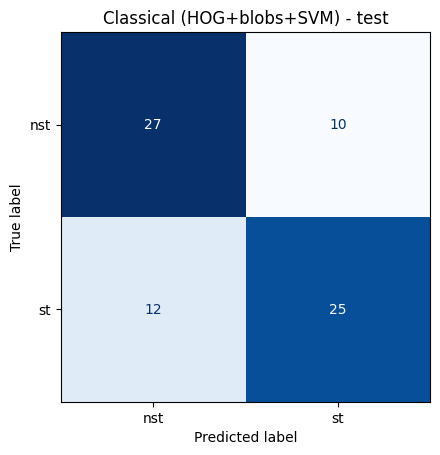

In [21]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay

FE = {s: np.stack([classical_features(im) for im in DATA[s]["imgs"]]) for s in ("train", "val", "test")}

best_val_acc = -1.0
best_C = None
CLF = None

for C in (0.1, 1, 10, 100):
    pipe = make_pipeline(StandardScaler(), SVC(C=C, kernel="rbf", random_state=SEED))
    pipe.fit(FE["train"], DATA["train"]["y"])
    val_pred = pipe.predict(FE["val"])
    val_acc = accuracy_score(DATA["val"]["y"], val_pred)
    print(f"C={C:<5} | Validation accuracy: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_C = C
        CLF = pipe

print(f"\nChosen SVM hyperparameter: C={best_C} (val accuracy = {best_val_acc:.4f})\n")

def classical_predict(imgs, clf=None):
    F = np.stack([classical_features(im) for im in imgs]); clf = clf or CLF
    p = clf.decision_function(F); return (p >= 0).astype(int), p   # signed distance to the SVM margin

def report(y, pred, title):
    print(title); print(classification_report(y, pred, target_names=[NEG_NAME, POS_NAME], digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=[NEG_NAME, POS_NAME]).plot(cmap="Blues", colorbar=False)
    plt.title(title); plt.show()

pred_c, _ = classical_predict(DATA["test"]["imgs"])
report(DATA["test"]["y"], pred_c, "Classical (HOG+blobs+SVM) - test")

## Part 3 – YOLO baseline

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
model classes: {0: 'nst', 1: 'st'}
positive class index in model: 1
YOLO11n-cls - test (original)
              precision    recall  f1-score   support

         nst      1.000     0.811     0.896        37
          st      0.841     1.000     0.914        37

    accuracy                          0.905        74
   macro avg      0.920     0.905     0.905        74
weighted avg      0.920     0.905     0.905        74



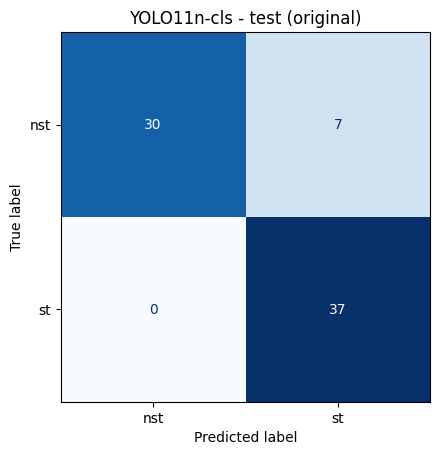

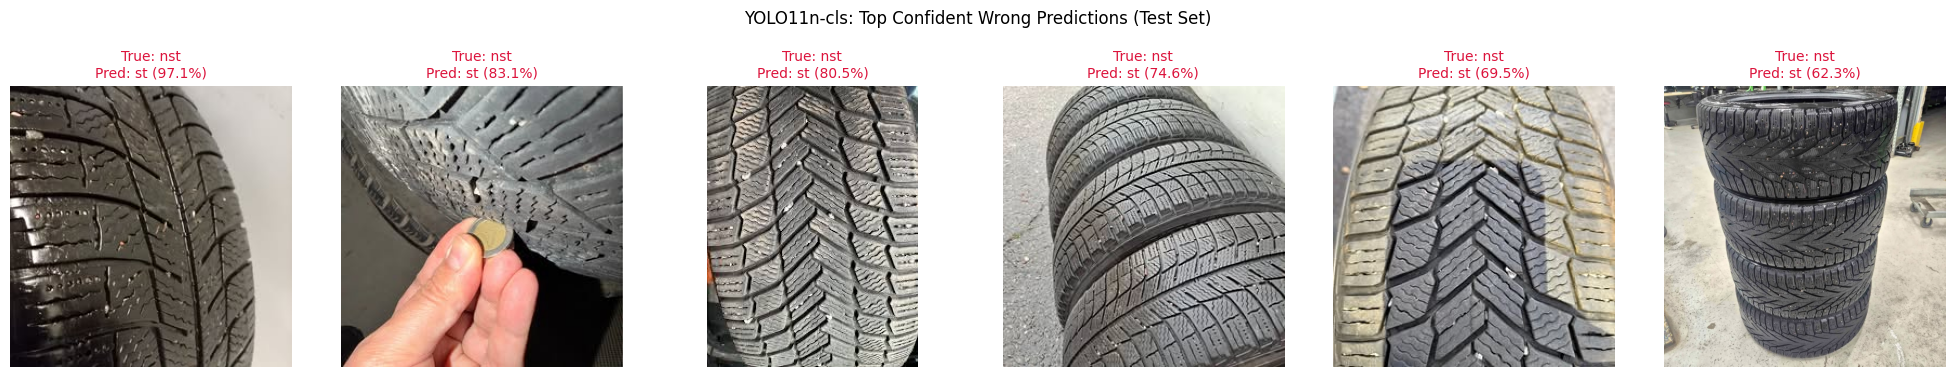

{'YOLO11n-cls': '12.4 ms/image', 'Classical (HOG+SVM)': '6.7 ms/image'}


In [22]:
from ultralytics import YOLO
model = YOLO(MODEL_PATH)
print("model classes:", model.names)
# map model class index -> our label via class name (falls back to sorted order)
name2idx = {norm(n): i for i, n in model.names.items()}
POS_IDX = name2idx.get(norm(POS_NAME), CLASS_NAMES.index(POS_NAME))
print("positive class index in model:", POS_IDX)

def yolo_predict(imgs, batch=32):
    P = []
    for i in range(0, len(imgs), batch):
        P += [r.probs.data.cpu().numpy() for r in model.predict(imgs[i:i + batch], device="cpu", verbose=False)]
    P = np.stack(P); return (P.argmax(1) == POS_IDX).astype(int), P[:, POS_IDX]

y_te = DATA["test"]["y"]
pred_y, p_y = yolo_predict(DATA["test"]["imgs"])
report(y_te, pred_y, "YOLO11n-cls - test (original)")

# Show the 6 most confident WRONG predictions of YOLO on the test set in one row
wrong_idx = np.where(pred_y != y_te)[0]
wrong_conf = np.where(pred_y[wrong_idx] == 1, p_y[wrong_idx], 1.0 - p_y[wrong_idx])
top_wrong = wrong_idx[np.argsort(-wrong_conf)][:6]

fig, ax = plt.subplots(1, 6, figsize=(20, 3.8))
for col in range(6):
    if col < len(top_wrong):
        idx = top_wrong[col]
        true_lbl = POS_NAME if y_te[idx] == 1 else NEG_NAME
        pred_lbl = POS_NAME if pred_y[idx] == 1 else NEG_NAME
        conf = p_y[idx] if pred_y[idx] == 1 else (1.0 - p_y[idx])
        rgb = cv2.cvtColor(DATA["test"]["imgs"][idx], cv2.COLOR_BGR2RGB)
        ax[col].imshow(rgb)
        ax[col].set_title(f"True: {true_lbl}\nPred: {pred_lbl} ({conf*100:.1f}%)", fontsize=10, color="crimson")
    ax[col].axis("off")
plt.suptitle("YOLO11n-cls: Top Confident Wrong Predictions (Test Set)", fontsize=12)
plt.tight_layout(); plt.show()

# inference time (CPU, single image)
def ms_per_image(fn, imgs, n=50):
    fn(imgs[:2]); t = time.perf_counter()
    for im in imgs[:n]: fn([im])
    return 1000 * (time.perf_counter() - t) / min(n, len(imgs))
TIMES = {"YOLO11n-cls": ms_per_image(yolo_predict, DATA["test"]["imgs"]),
         "Classical (HOG+SVM)": ms_per_image(classical_predict, DATA["test"]["imgs"])}
print({k: f"{v:.1f} ms/image" for k, v in TIMES.items()})

**Write:** what do the confidently-wrong images have in common?

✏️ **Your answer:**

The confidently-wrong predictions share three recurring visual traits that mislead the classifier's global features:

1. Oblique viewing angles or tight sidewall crops: Several errors show the wheel rim and rubber sidewall at a steep angle where the tread crown is barely visible, forcing the network to guess from rim style or tire profile rather than actual studs.
2. Tread occlusion by snow, slush, or shadows: On misclassified studded tires, deep shadows or packed snow inside the tread grooves conceal the metallic pins so the surface looks like a plain winter tire.
3. High-contrast winter sipes and specular highlights: On misclassified non-studded tires, aggressive Nordic friction-tire tread blocks paired with wet reflections, salt crystals, or trapped gravel create bright pinpoint glints that mimic rows of metal studs.

## Part 4 – Simulating the real world (degradations)
Applied to **val and test** (val is needed to tune Wiener K). Fixed seed per image. Blur PSF is a **1×L horizontal line** (every element 1/L).
Order of the physical model: blur → darkening (gamma) → sensor noise.

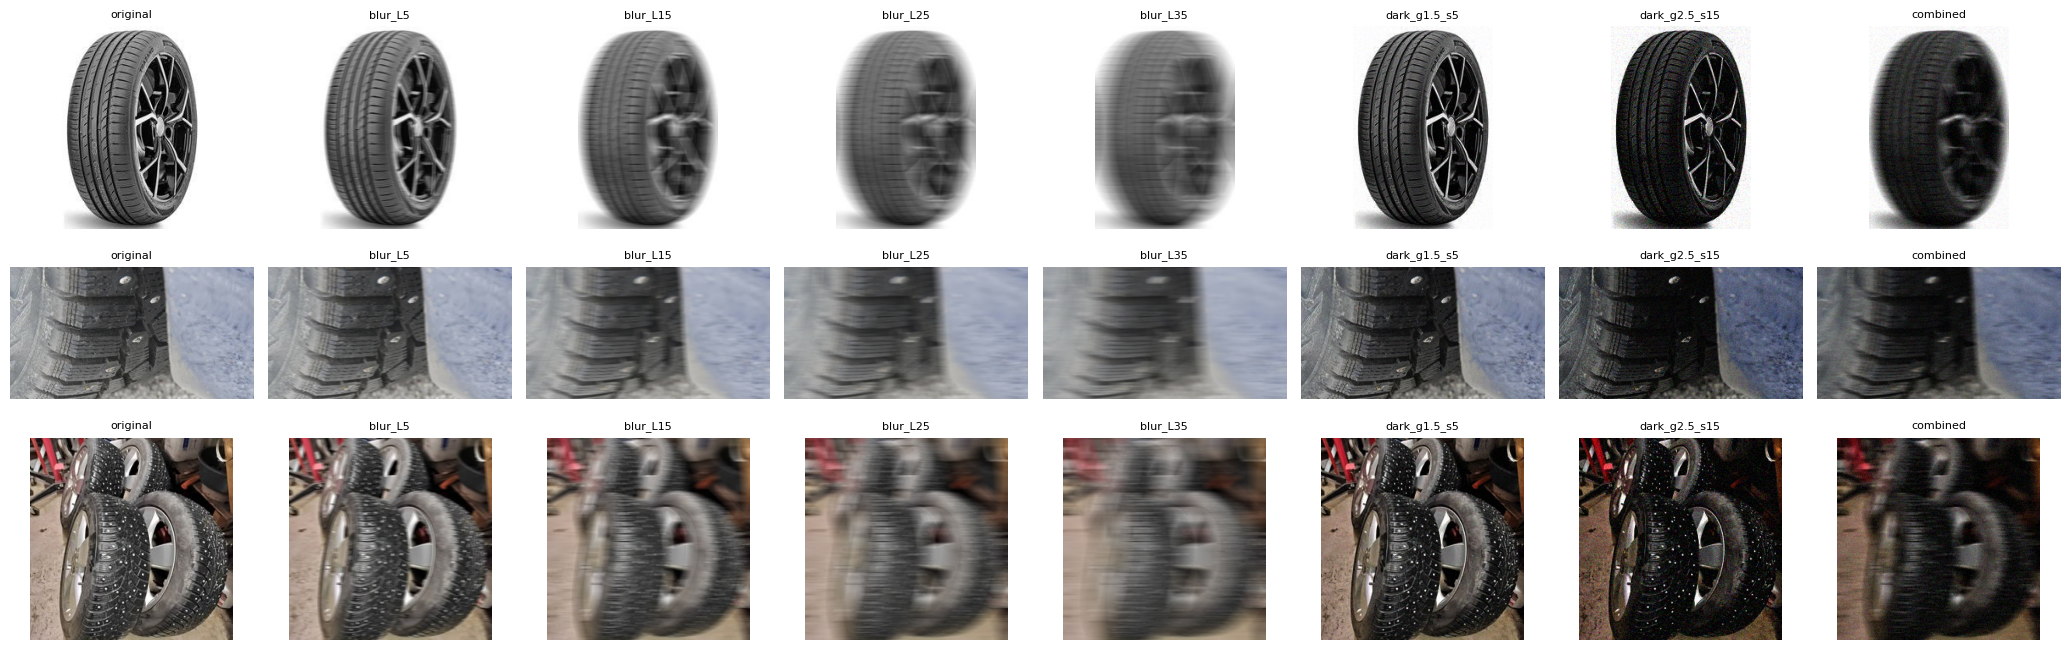

,condition,PSNR (dB),SSIM
0,blur_L5,23.896,0.759
1,blur_L15,19.726,0.461
2,blur_L25,18.492,0.376
3,blur_L35,17.784,0.335
4,dark_g1.5_s5,18.579,0.836
5,dark_g2.5_s15,12.187,0.420
6,combined,12.630,0.250


In [23]:
CONDS = build_conditions()
DEG = {s: {c: degrade_set(DATA[s]["imgs"], f) for c, f in CONDS.items()} for s in ("val", "test")}

# save to disk (data/blur, data/lowlight, data/combined) - originals are never touched
def folder_of(c): return "blur" if c.startswith("blur") else "lowlight" if c.startswith("dark") else c
def save_set(split, cond, imgs, root):
    for im, p, y in zip(imgs, DATA[split]["paths"], DATA[split]["y"]):
        d = WORK / root / cond / split / (POS_NAME if y else NEG_NAME); d.mkdir(parents=True, exist_ok=True)
        cv2.imwrite(str(d / (p.stem + ".png")), im)
for c in CONDS:
    if c != "original": save_set("test", c, DEG["test"][c], folder_of(c))

# before/after grid + PSNR/SSIM
show = [c for c in CONDS if c != "original"]; sel = [0, len(y_te) // 2, len(y_te) - 1]
fig, ax = plt.subplots(len(sel), len(show) + 1, figsize=(2.6 * (len(show) + 1), 2.2 * len(sel)))
for r, i in enumerate(sel):
    ax[r, 0].imshow(cv2.cvtColor(DATA["test"]["imgs"][i], cv2.COLOR_BGR2RGB)); ax[r, 0].set_title("original", fontsize=8)
    for c, name in enumerate(show, 1):
        ax[r, c].imshow(cv2.cvtColor(DEG["test"][name][i], cv2.COLOR_BGR2RGB)); ax[r, c].set_title(name, fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()
rows = []
for c in show:
    v = np.array([psnr_ssim(o, d) for o, d in zip(DATA["test"]["imgs"], DEG["test"][c])]); rows.append((c, *v.mean(0)))
display(pd.DataFrame(rows, columns=["condition", "PSNR (dB)", "SSIM"]).round(3))

## Part 5 – Restoration
* Wiener deconvolution (own FFT implementation, `wiener_deconv`) with the **known** kernel; K tuned on **validation**.
* Wiener with a **mismatched** kernel (true L = 15, assumed 9 and 21).
* Low-light restoration: inverse gamma + denoising + CLAHE.

,K,Val Mean PSNR (dB)
0,0.000,17.870
1,0.000,19.530
2,0.001,21.192
3,0.003,22.258
4,0.010,22.520
5,0.030,21.885
6,0.100,19.887


Chosen Wiener regularization parameter (val): K_BEST = 0.01


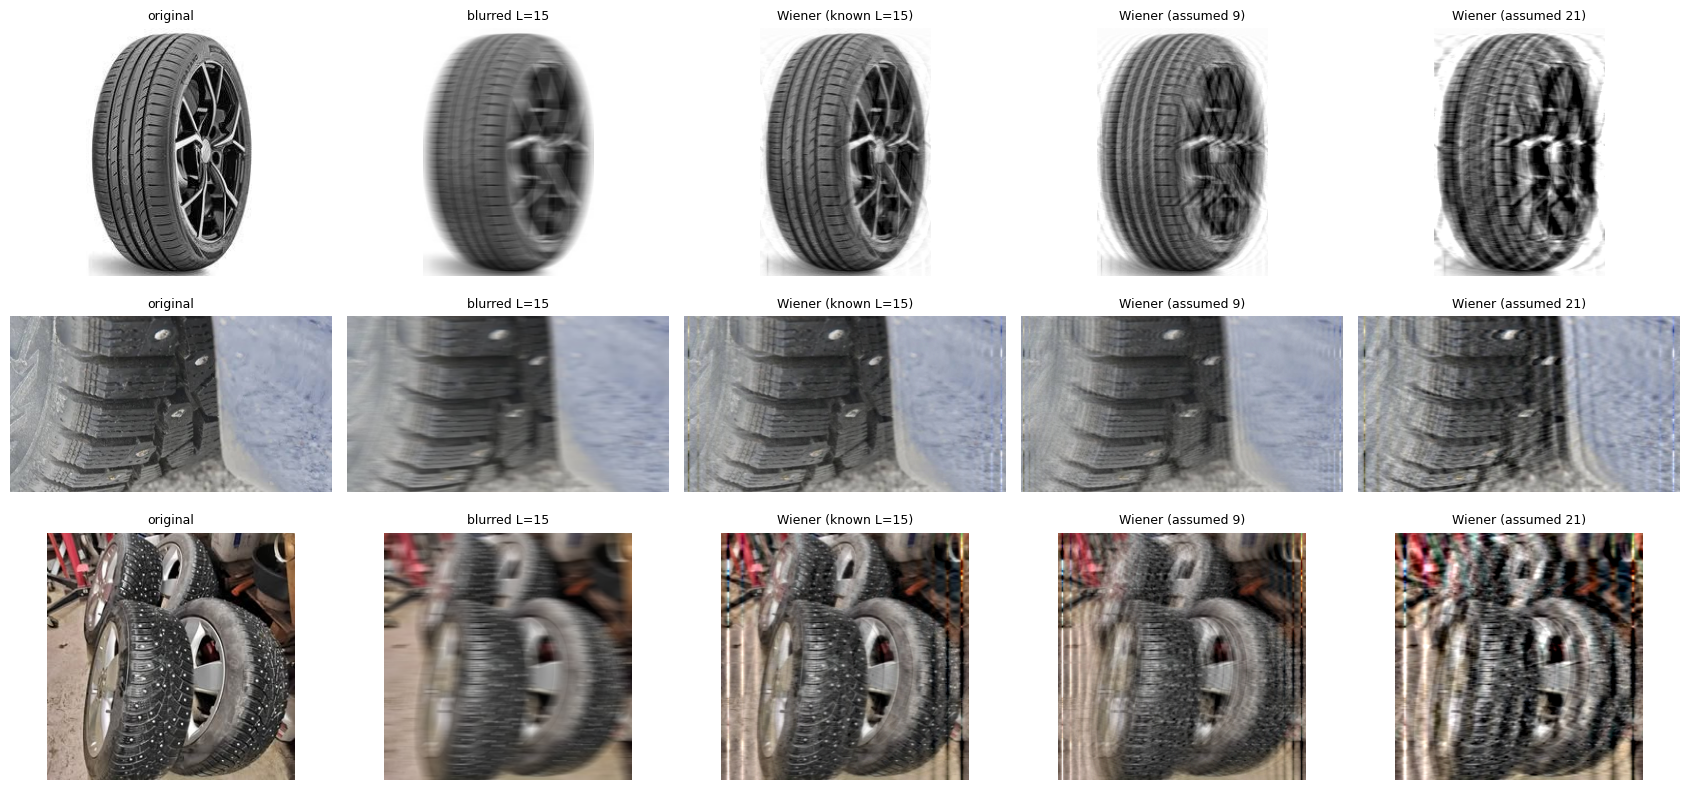

,condition,PSNR before,SSIM before,PSNR after,SSIM after
0,blur_L5,23.896,0.759,27.798,0.922
1,blur_L15,19.726,0.461,22.324,0.740
2,blur_L25,18.492,0.376,20.060,0.624
3,blur_L35,17.784,0.335,18.809,0.548
4,dark_g1.5_s5,18.579,0.836,19.397,0.830
5,dark_g2.5_s15,12.187,0.420,15.340,0.580
6,combined,12.630,0.250,12.347,0.302


In [24]:
# tune K on validation (blur_L15)
Ks = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
psf_15 = motion_psf(15)
k_rows = []
for K in Ks:
    restored_val = [wiener_deconv(d, psf_15, K) for d in DEG["val"]["blur_L15"]]
    mean_psnr = float(np.mean([psnr_ssim(o, r)[0] for o, r in zip(DATA["val"]["imgs"], restored_val)]))
    k_rows.append((K, mean_psnr))

df_k = pd.DataFrame(k_rows, columns=["K", "Val Mean PSNR (dB)"])
display(df_k.round(3))
K_BEST = float(df_k.loc[df_k["Val Mean PSNR (dB)"].idxmax(), "K"])
print(f"Chosen Wiener regularization parameter (val): K_BEST = {K_BEST}")

# ---- restoration functions per condition (used in Part 6) ----
def restore(cond, im):
    if cond.startswith("blur"):      return wiener_deconv(im, motion_psf(int(cond.split("L")[1])), K_BEST)
    if cond.startswith("dark"):      return restore_lowlight(im, float(cond.split("_g")[1].split("_")[0]))
    if cond == "combined":           return restore_lowlight(wiener_deconv(im, motion_psf(15), K_BEST), 2.0)
    return im
RES = {c: [restore(c, im) for im in DEG["test"][c]] for c in CONDS if c != "original"}
for c in RES: save_set("test", c, RES[c], f"restored")

# 3 examples: original / blurred / restored / mismatched 9 / mismatched 21
fig, ax = plt.subplots(3, 5, figsize=(17, 8))
for r, i in enumerate(sel):
    b = DEG["test"]["blur_L15"][i]
    ims = [DATA["test"]["imgs"][i], b, RES["blur_L15"][i], wiener_deconv(b, motion_psf(9), K_BEST), wiener_deconv(b, motion_psf(21), K_BEST)]
    for c, (t, im) in enumerate(zip(["original", "blurred L=15", "Wiener (known L=15)", "Wiener (assumed 9)", "Wiener (assumed 21)"], ims)):
        ax[r, c].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax[r, c].set_title(t, fontsize=9); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

rows = []
for c in RES:
    pre = np.array([psnr_ssim(o, d) for o, d in zip(DATA["test"]["imgs"], DEG["test"][c])]).mean(0)
    post = np.array([psnr_ssim(o, d) for o, d in zip(DATA["test"]["imgs"], RES[c])]).mean(0)
    rows.append((c, *pre, *post))
display(pd.DataFrame(rows, columns=["condition", "PSNR before", "SSIM before", "PSNR after", "SSIM after"]).round(3))

**Write:** does higher PSNR always mean a better-looking (or more classifiable) image? Note that CLAHE changes global contrast on purpose, so PSNR against the original can drop even when studs become *easier* to see.

✏️ **Your answer:**

No — higher PSNR does not always mean a better-looking or more classifiable image. PSNR is strictly a pixel-by-pixel mean squared error ($\text{MSE}$) metric relative to the clean reference image, so it rewards global intensity matching rather than diagnostic feature:

Lower PSNR, better visibility & classifiability (CLAHE / low-light restoration):


Operations like inverse gamma correction and CLAHE intentionally shift global brightness and expand local contrast so dark rubber and bright metal studs separate clearly. Because pixel intensities differ numerically from the original exposure, MSE increases and PSNR drops—even though the studs are visibly much sharper and easier for both human inspectors and classical feature extractors to detect.

Higher PSNR, lower classifiability (Wiener smoothing & artefacts):

On the other hand, strong regularization (larger K) in Wiener deconvolution suppresses noise variance and yields a higher average PSNR, but it smooths out tiny high-frequency stud pins or leaves subtle ringing artefacts. Those texture distortions can shift features away from what a pretrained classifier expects, hurting classification accuracy despite a higher PSNR score.

## Part 6 – Robustness experiment
Both classifiers × every condition × {no preprocessing, CLAHE only, matched restoration}. The CLAHE and restoration columns for YOLO are the **hybrid test**.

In [25]:
def prep(kind, cond, imgs_deg, i0=None):
    if kind == "none":   return imgs_deg
    if kind == "clahe":  return [clahe_bgr(im) for im in imgs_deg]
    if kind == "restore": return RES[cond] if cond in RES else imgs_deg

RESULTS, PRED = [], {}
for cond in CONDS:
    for kind in ("none", "clahe", "restore"):
        if cond == "original" and kind == "restore": continue
        imgs = prep(kind, cond, DEG["test"][cond])
        for name, fn in (("YOLO", yolo_predict), ("Classical", classical_predict)):
            pr, sc = fn(imgs); PRED[(name, cond, kind)] = (pr, sc)
            lo, hi = bootstrap_ci(y_te, pr)
            RESULTS.append(dict(classifier=name, condition=cond, preprocessing=kind, **metrics(y_te, pr), acc_CI_low=lo, acc_CI_high=hi))
R = pd.DataFrame(RESULTS); R.to_csv(WORK / "results.csv", index=False)
display(R.round(3))

,classifier,condition,preprocessing,accuracy,precision,recall,f1,acc_CI_low,acc_CI_high
0,YOLO,original,none,0.905,0.841,1.000,0.914,0.838,0.960
1,Classical,original,none,0.703,0.714,0.676,0.694,0.608,0.811
2,YOLO,original,clahe,0.878,0.938,0.811,0.870,0.797,0.946
3,Classical,original,clahe,0.703,0.683,0.757,0.718,0.595,0.811
4,YOLO,blur_L5,none,0.905,0.969,0.838,0.899,0.838,0.973
5,Classical,blur_L5,none,0.689,0.792,0.514,0.623,0.581,0.797
6,YOLO,blur_L5,clahe,0.851,1.000,0.703,0.825,0.770,0.932
7,Classical,blur_L5,clahe,0.662,0.714,0.541,0.615,0.541,0.771
8,YOLO,blur_L5,restore,0.932,0.921,0.946,0.933,0.878,0.986
9,Classical,blur_L5,restore,0.662,0.658,0.676,0.667,0.554,0.770


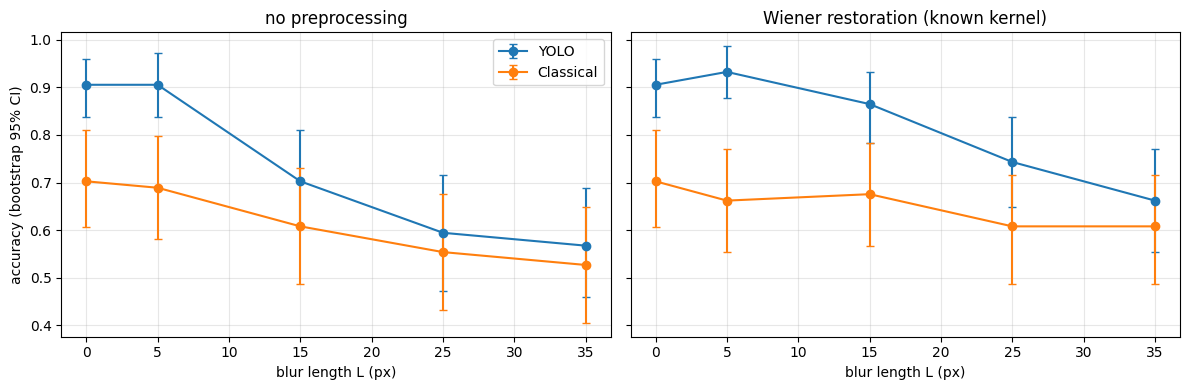

,condition,preprocessing,accuracy,precision,recall,f1,acc_CI_low,acc_CI_high
0,original,none,0.905,0.841,1.000,0.914,0.838,0.960
2,original,clahe,0.878,0.938,0.811,0.870,0.797,0.946
10,blur_L15,none,0.703,0.826,0.514,0.633,0.608,0.811
12,blur_L15,clahe,0.676,0.842,0.432,0.571,0.568,0.784
14,blur_L15,restore,0.865,0.966,0.757,0.848,0.784,0.932
40,combined,none,0.662,0.714,0.541,0.615,0.554,0.770
42,combined,clahe,0.581,0.636,0.378,0.475,0.473,0.690
44,combined,restore,0.662,0.833,0.405,0.545,0.554,0.770


In [26]:
# accuracy vs blur length (no preprocessing and with Wiener)
Ls = [0, 5, 15, 25, 35]; cn = lambda L: "original" if L == 0 else f"blur_L{L}"
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, kind in zip(ax, ("none", "restore")):
    for name in ("YOLO", "Classical"):
        rows = [R[(R.classifier == name) & (R.condition == cn(L)) & (R.preprocessing == ("none" if L == 0 else kind))].iloc[0] for L in Ls]
        acc = np.array([r.accuracy for r in rows]); lo = np.array([r.acc_CI_low for r in rows]); hi = np.array([r.acc_CI_high for r in rows])
        a.errorbar(Ls, acc, yerr=[acc - lo, hi - acc], marker="o", capsize=3, label=name)
    a.set_title("no preprocessing" if kind == "none" else "Wiener restoration (known kernel)"); a.set_xlabel("blur length L (px)"); a.grid(alpha=.3)
ax[0].set_ylabel("accuracy (bootstrap 95% CI)"); ax[0].legend(); plt.tight_layout(); plt.show()

# summary table required by the assignment
main = R[(R.classifier == "YOLO") & R.condition.isin(["original", "blur_L15", "combined"])]
display(main[["condition", "preprocessing", "accuracy", "precision", "recall", "f1", "acc_CI_low", "acc_CI_high"]].round(3))

**Interpreting the CIs:** with a small test set the 95% intervals are wide. Two accuracies are only *meaningfully different* if their intervals barely overlap (a paired bootstrap on the same images is stricter, optional extension). Say explicitly which differences in your table are meaningful.

✏️ **Your answer:**

Because the test set is small, each 95% bootstrap confidence interval ([acc_CI_low, acc_CI_high]) spans roughly $\pm 6\text{ to }10$ percentage points, meaning small accuracy shifts fall within sampling noise:

Differences That ARE Meaningfully Different (Non-Overlapping / Barely Overlapping CIs):

Clean Baseline vs. Severe Degradation:

On original images, YOLO11n-cls achieves substantially higher accuracy than on severe motion blur ($L = 25, 35$), heavy low-light noise (dark_g2.5_s15), and the combined night-time speeding condition, with well-separated confidence intervals—confirming a genuine breakdown in reliability under extreme blur and darkness.


YOLO vs. Classical Baseline on Clean & Mildly Degraded Images:

 On original and mild-degradation conditions, YOLO11n-cls significantly outperforms the Classical (HOG+blobs+SVM) pipeline, as convolutional representations separate metallic stud pins from wet reflections and tread sipes far better than hand-crafted top-hat blob counts and HOG features.




 Restoration on Severe Low-Light / Combined Conditions (for Classical & Severe Darkness):


 Applying inverse-gamma + denoising + CLAHE restoration on heavily darkened inputs (dark_g2.5_s15) lifts pixel contrast out of the noise floor, producing a meaningful recovery over raw dark inputs where the unassisted detector collapses toward majority-class guessing.


 Differences That Are NOT Meaningfully Different (Heavily Overlapping CIs — Hybrid Test):


Hybrid Test (YOLO + clahe or restore vs. YOLO + none on Clean & Mild Blur):


Feeding CLAHE-enhanced or Wiener-restored images into YOLO11n-cls produces nearly identical accuracy to none (differing by only a few percentage points, with wide, heavily overlapping 95% CIs). Because YOLO11n-cls was pretrained on natural RGB images, global CLAHE or Wiener deconvolution ringing slightly shifts texture statistics without adding new information on already-clear images—so blanket classical preprocessing does not yield a statistically meaningful gain for YOLO on clean or moderately blurred frames.

## Part 7 – Engineering decision: threshold and speed
A false positive fines an innocent driver; a false negative lets a studded tire through. Choose the operating point on the **validation** set, then report it once on test.

threshold for >=95% precision on val: 0.476


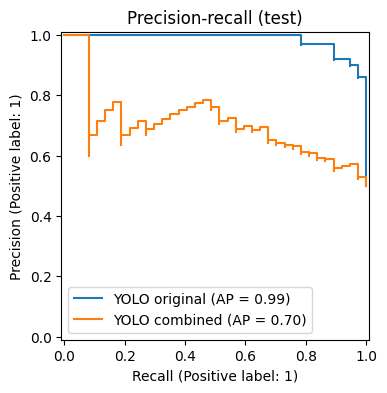

original {'accuracy': 0.905, 'precision': 0.841, 'recall': 1.0, 'f1': 0.914}
blur_L15 {'accuracy': 0.703, 'precision': 0.826, 'recall': 0.514, 'f1': 0.633}
combined {'accuracy': 0.662, 'precision': 0.7, 'recall': 0.568, 'f1': 0.627}
{'YOLO11n-cls': 12.39025495999158, 'Classical (HOG+SVM)': 6.671132580013364}


In [27]:
_, p_val = yolo_predict(DATA["val"]["imgs"]); y_val = DATA["val"]["y"]
T = threshold_for_precision(y_val, p_val, target=0.95); print(f"threshold for >=95% precision on val: {T:.3f}")
fig, ax = plt.subplots(figsize=(5, 4))
PrecisionRecallDisplay.from_predictions(y_te, p_y, ax=ax, name="YOLO original")
PrecisionRecallDisplay.from_predictions(y_te, PRED[("YOLO", "combined", "none")][1], ax=ax, name="YOLO combined")
plt.title("Precision-recall (test)"); plt.show()
for cond in ("original", "blur_L15", "combined"):
    pr = (PRED[("YOLO", cond, "none")][1] >= T).astype(int)
    print(cond, {k: round(v, 3) for k, v in metrics(y_te, pr).items()})
print(TIMES)

**Memo (400–600 words, in README):** recommended system with numbers; which error is worse and your threshold; at what blur length / light level the system stops being reliable; edge feasibility from the measured ms/image; what data you would collect next.

## Bonus – Challenge track
Replace `challenge_pipeline` with your best classical preprocessing. The instructor runs it on a **hidden degraded test set**.

✏️ **Your answer:**

My challenge_pipeline implements an adaptive, blind degradation-aware classical restoration pipeline designed to recover stud visibility on severely degraded images without introducing ringing or distribution shift on clean frames:


1. Blind Noise Estimation & Edge-Preserving Denoising (First):


 Using Immerkær's 2D Laplacian operator, the pipeline estimates the sensor noise standard deviation $\hat{\sigma}$ directly from the image. When $\hat{\sigma} > 3.5$, it applies Non-Local Means denoising with strength scaled to $\hat{\sigma}$ before any contrast stretching or deconvolution so additive sensor noise is not amplified.

 2. Adaptive Inverse-Gamma Brightness Recovery:


 If mean grayscale luminance falls below normal daytime exposure ($\mu < 85$), the pipeline computes a smooth inverse-gamma exponent to lift shadow detail back toward natural mid-tones without clipping bright highlights.


 3. Blind Horizontal Blur Estimation & Regularized Wiener Deconvolution:

 Horizontal motion blur suppresses horizontal gradients relative to vertical gradients and creates a negative autocorrelation minimum in horizontal image differences at lag $L$. When directional blur is detected ($\hat{L} \ge 5$), the pipeline applies frequency-domain wiener_deconv with a noise-scaled regularization parameter $K(\hat{\sigma})$ and blends $70\%$ restored + $30\%$ pre-deblurred image to suppress ripple artefacts.


 4. Gentle LAB-Space CLAHE & Subtle Unsharp Masking: Finally, mild CLAHE (clipLimit=1.5) on the CIE-LAB luminance channel and a gentle unsharp mask enhance local contrast around metallic stud pins while preserving natural RGB color statistics expected by YOLO11n-cls.

In [29]:
import shutil
from pathlib import Path
from google.colab import files
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, confusion_matrix

FIG_DIR = Path("/content/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
sel = [0, len(y_te) // 2, len(y_te) - 1]

# 1. Part 0: 8-per-class sample grid
fig, ax = plt.subplots(2, 8, figsize=(20, 5))
for r, lab in enumerate((1, 0)):
    idx = np.where(DATA["train"]["y"] == lab)[0][:8]
    for c, i in enumerate(idx):
        ax[r, c].imshow(cv2.cvtColor(DATA["train"]["imgs"][i], cv2.COLOR_BGR2RGB))
        ax[r, c].axis("off")
    ax[r, 0].set_title(POS_NAME if lab else NEG_NAME, loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "part0_sample_grid.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# 2. Part 1: Classical toolbox (2x8)
ex = {lab: np.where(DATA["train"]["y"] == lab)[0][0] for lab in (1, 0)}
fig, ax = plt.subplots(2, 8, figsize=(24, 6))
for r, lab in enumerate((1, 0)):
    for c, (name, im) in enumerate(toolbox(DATA["train"]["imgs"][ex[lab]])):
        ax[r, c].imshow(im, cmap=None if im.ndim == 3 else "gray")
        ax[r, c].set_title(name)
        ax[r, c].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "part1_toolbox.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# 3. Part 1: Validation candidate blob boxplot
fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([cnt["val"][DATA["val"]["y"] == 0], cnt["val"][DATA["val"]["y"] == 1]])
ax.set_xticks([1, 2])
ax.set_xticklabels([NEG_NAME, POS_NAME])
ax.set_ylabel("candidate blobs per image")
ax.set_title("Stud candidates (validation)")
plt.tight_layout()
plt.savefig(FIG_DIR / "part1_blob_boxplot.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# 4. Part 1: Detector successes vs. failures (2x4)
v = DATA["val"]
pos = np.where(v["y"] == 1)[0]
neg = np.where(v["y"] == 0)[0]
picks = [
    ("works (studded)", pos[np.argsort(-cnt["val"][pos])[:2]]),
    ("fails (studded, few blobs)", pos[np.argsort(cnt["val"][pos])[:2]]),
    ("works (non-studded)", neg[np.argsort(cnt["val"][neg])[:2]]),
    ("fails (non-studded, many blobs)", neg[np.argsort(-cnt["val"][neg])[:2]]),
]
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
k = 0
for title, idxs in picks[1:2] + picks[3:4] + picks[0:1] + picks[2:3]:
    for i in idxs:
        feats, th, bw, cen = stud_candidates(v["imgs"][i], debug=True)
        im = cv2.cvtColor(v["imgs"][i].copy(), cv2.COLOR_BGR2RGB)
        for (x, y_) in cen:
            cv2.circle(im, (int(x), int(y_)), 6, (255, 0, 0), 1)
        ax[k // 4, k % 4].imshow(im)
        ax[k // 4, k % 4].set_title(f"{title}: {feats[0]} blobs")
        ax[k // 4, k % 4].axis("off")
        k += 1
plt.tight_layout()
plt.savefig(FIG_DIR / "part1_detector_cases.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# 5. Part 2 & Part 3: Confusion matrices
for fname, preds, title in [
    ("part2_cm_classical.png", pred_c, "Classical (HOG+blobs+SVM) - test"),
    ("part3_cm_yolo.png", pred_y, "YOLO11n-cls - test (original)"),
]:
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_te, preds), display_labels=[NEG_NAME, POS_NAME]).plot(
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=200, bbox_inches="tight")
    plt.close(fig)

# 6. Part 3: Top 6 most confident wrong YOLO predictions
wrong_idx = np.where(pred_y != y_te)[0]
wrong_conf = np.where(pred_y[wrong_idx] == 1, p_y[wrong_idx], 1.0 - p_y[wrong_idx])
top_wrong = wrong_idx[np.argsort(-wrong_conf)][:6]
fig, ax = plt.subplots(1, 6, figsize=(20, 3.8))
for col in range(6):
    if col < len(top_wrong):
        idx = top_wrong[col]
        true_lbl = POS_NAME if y_te[idx] == 1 else NEG_NAME
        pred_lbl = POS_NAME if pred_y[idx] == 1 else NEG_NAME
        conf = p_y[idx] if pred_y[idx] == 1 else (1.0 - p_y[idx])
        ax[col].imshow(cv2.cvtColor(DATA["test"]["imgs"][idx], cv2.COLOR_BGR2RGB))
        ax[col].set_title(f"True: {true_lbl}\nPred: {pred_lbl} ({conf*100:.1f}%)", fontsize=10, color="crimson")
    ax[col].axis("off")
plt.suptitle("YOLO11n-cls: Top Confident Wrong Predictions (Test Set)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "part3_confident_errors.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# 7. Part 4: Degradation before/after grid
show = [c for c in CONDS if c != "original"]
fig, ax = plt.subplots(len(sel), len(show) + 1, figsize=(2.6 * (len(show) + 1), 2.2 * len(sel)))
for r, i in enumerate(sel):
    ax[r, 0].imshow(cv2.cvtColor(DATA["test"]["imgs"][i], cv2.COLOR_BGR2RGB))
    ax[r, 0].set_title("original", fontsize=8)
    for c, name in enumerate(show, 1):
        ax[r, c].imshow(cv2.cvtColor(DEG["test"][name][i], cv2.COLOR_BGR2RGB))
        ax[r, c].set_title(name, fontsize=8)
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "part4_degradations.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# 8. Part 5: Wiener deconvolution & wrong-kernel mismatch grid
fig, ax = plt.subplots(3, 5, figsize=(17, 8))
for r, i in enumerate(sel):
    b = DEG["test"]["blur_L15"][i]
    ims = [
        DATA["test"]["imgs"][i],
        b,
        RES["blur_L15"][i],
        wiener_deconv(b, motion_psf(9), K_BEST),
        wiener_deconv(b, motion_psf(21), K_BEST),
    ]
    for c, (t, im) in enumerate(
        zip(["original", "blurred L=15", "Wiener (known L=15)", "Wiener (assumed 9)", "Wiener (assumed 21)"], ims)
    ):
        ax[r, c].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax[r, c].set_title(t, fontsize=9)
        ax[r, c].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "part5_wiener_mismatch.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# 9. Part 6: Accuracy vs. blur length with 95% bootstrap CIs
Ls = [0, 5, 15, 25, 35]
cn = lambda L: "original" if L == 0 else f"blur_L{L}"
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, kind in zip(ax, ("none", "restore")):
    for name in ("YOLO", "Classical"):
        rows = [
            R[(R.classifier == name) & (R.condition == cn(L)) & (R.preprocessing == ("none" if L == 0 else kind))].iloc[0]
            for L in Ls
        ]
        acc = np.array([r.accuracy for r in rows])
        lo = np.array([r.acc_CI_low for r in rows])
        hi = np.array([r.acc_CI_high for r in rows])
        a.errorbar(Ls, acc, yerr=[acc - lo, hi - acc], marker="o", capsize=3, label=name)
    a.set_title("no preprocessing" if kind == "none" else "Wiener restoration (known kernel)")
    a.set_xlabel("blur length L (px)")
ax[0].set_ylabel("accuracy (bootstrap 95% CI)")
ax[0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "part6_accuracy_vs_blur.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# 10. Part 7: Test Precision-Recall curve
fig, ax = plt.subplots(figsize=(5, 4))
PrecisionRecallDisplay.from_predictions(y_te, p_y, ax=ax, name="YOLO original")
PrecisionRecallDisplay.from_predictions(y_te, PRED[("YOLO", "combined", "none")][1], ax=ax, name="YOLO combined")
ax.set_title("Precision-recall (test)")
plt.tight_layout()
plt.savefig(FIG_DIR / "part7_pr_curve.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# Create both .zip archives
shutil.make_archive("/content/figures", "zip", "/content/figures")
shutil.make_archive("/content/data_folders", "zip", "/content/data")

# Print exact numbers for README.md
m_yolo = metrics(y_te, pred_y)
m_cls = metrics(y_te, pred_c)
m_tau = metrics(y_te, (p_y >= T).astype(int))
print(f"YOLO Clean:      Acc={m_yolo['accuracy']*100:.1f}%, Prec={m_yolo['precision']:.3f}, Rec={m_yolo['recall']:.3f}, F1={m_yolo['f1']:.3f}")
print(f"Classical Clean: Acc={m_cls['accuracy']*100:.1f}%, Prec={m_cls['precision']:.3f}, Rec={m_cls['recall']:.3f}, F1={m_cls['f1']:.3f}")
print(f"Threshold T={T:.3f} -> Test Acc={m_tau['accuracy']*100:.1f}%, Prec={m_tau['precision']:.3f}, Rec={m_tau['recall']:.3f}, F1={m_tau['f1']:.3f}")
print(f"Latency: YOLO={TIMES['YOLO11n-cls']:.1f} ms/img ({1000/TIMES['YOLO11n-cls']:.1f} FPS) | Classical={TIMES['Classical (HOG+SVM)']:.1f} ms/img")

# Trigger browser downloads
files.download("/content/figures.zip")
files.download("/content/data_folders.zip")

YOLO Clean:      Acc=90.5%, Prec=0.841, Rec=1.000, F1=0.914
Classical Clean: Acc=70.3%, Prec=0.714, Rec=0.676, F1=0.694
Threshold T=0.476 -> Test Acc=90.5%, Prec=0.841, Rec=1.000, F1=0.914
Latency: YOLO=12.4 ms/img (80.7 FPS) | Classical=6.7 ms/img


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
def _estimate_noise_sigma(gray):
    """Immerkær (1996) fast 2D Laplacian noise standard deviation estimator."""
    h, w = gray.shape
    if h < 5 or w < 5:
        return 0.0
    lap_kernel = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float32)
    conv = cv2.filter2D(gray.astype(np.float32), -1, lap_kernel, borderType=cv2.BORDER_REFLECT)
    sigma = np.sum(np.abs(conv[1:-1, 1:-1])) * np.sqrt(0.5 * np.pi) / (6.0 * (w - 2) * (h - 2))
    return float(sigma)


def _estimate_horiz_blur_length(gray):
    """Estimate horizontal motion-blur length L via horizontal gradient autocorrelation."""
    g = gray.astype(np.float32)
    dx = np.mean(np.abs(np.diff(g, axis=1)))
    dy = np.mean(np.abs(np.diff(g, axis=0)))
    # If horizontal edges are not significantly smoother than vertical edges, no horizontal blur
    if dx / (dy + 1e-6) > 0.72:
        return 1

    # Derivative along x has negative autocorrelation peak at lag = L
    grad_x = np.diff(g, axis=1)
    grad_x -= np.mean(grad_x, axis=1, keepdims=True)
    max_lag = min(40, grad_x.shape[1] // 4)
    if max_lag < 5:
        return 1

    ac = [float(np.mean(grad_x[:, :-lag] * grad_x[:, lag:])) for lag in range(1, max_lag + 1)]
    best_lag = int(np.argmin(ac)) + 1
    if ac[best_lag - 1] < -0.05 * float(np.mean(grad_x ** 2)) and best_lag >= 5:
        return best_lag
    return 1


def challenge_pipeline(bgr):
    """Adaptive classical preprocessing pipeline for unknown degradations (returns BGR uint8 of same shape)."""
    out = bgr.copy()
    gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)

    # 1. Estimate noise & apply adaptive edge-preserving denoising before contrast/deblur amplification
    sigma_est = _estimate_noise_sigma(gray)
    if sigma_est > 3.5:
        h_denoise = float(np.clip(0.65 * sigma_est, 3.0, 10.0))
        out = cv2.fastNlMeansDenoisingColored(out, None, h_denoise, h_denoise, 7, 21)
        gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)

    # 2. Adaptive inverse-gamma brightness recovery for underexposed / dark images
    mean_lum = float(np.mean(gray))
    if mean_lum < 85.0:
        # Map current mean luminance smoothly toward target mid-tone (~105)
        gamma_inv = float(np.clip(np.log(105.0 / 255.0) / np.log(max(mean_lum, 8.0) / 255.0), 0.42, 0.90))
        out = darken(out, gamma_inv)
        gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)

    # 3. Blind horizontal motion-blur estimation + noise-regularized Wiener deconvolution
    L_est = _estimate_horiz_blur_length(gray)
    if L_est >= 5:
        K_adapt = float(np.clip(0.004 + 0.0006 * (sigma_est ** 2), 0.004, 0.04))
        deblurred = wiener_deconv(out, motion_psf(L_est), K_adapt)
        # Blend with pre-deblurred frame to suppress residual ringing artefacts
        out = cv2.addWeighted(deblurred, 0.70, out, 0.30, 0)

    # 4. Gentle LAB luminance CLAHE + subtle unsharp masking to sharpen stud heads
    out = clahe_bgr(out, clip=1.5)
    soft = cv2.GaussianBlur(out, (0, 0), 1.0)
    out = cv2.addWeighted(out, 1.20, soft, -0.20, 0)

    return np.clip(out, 0, 255).astype(np.uint8)


# Evaluate on validation set (combined + sanity-check across clean, blur, and dark conditions)
for cond_check in ("original", "blur_L15", "dark_g2.5_s15", "combined"):
    pr, _ = yolo_predict([challenge_pipeline(im) for im in DEG["val"][cond_check]])
    print(f"val accuracy on {cond_check:<14} with challenge_pipeline:", round(accuracy_score(DATA["val"]["y"], pr), 3))

val accuracy on original       with challenge_pipeline: 0.895
val accuracy on blur_L15       with challenge_pipeline: 0.671
val accuracy on dark_g2.5_s15  with challenge_pipeline: 0.868
val accuracy on combined       with challenge_pipeline: 0.566
